# Direction 3 — Probabilistic (vMF) Grade Embeddings
## DeepDRiD Benchmark — Training, Baselines, Ablations, Calibration & Figures

Companion to the main, Direction 1 and Direction 2 notebooks for the `direction3-probabilistic-ordinal`
branch. Each DR grade is a von Mises–Fisher distribution on CLIP's unit sphere: a mean direction
(started from the zero-shot ICDR description ensemble) and a learned concentration κ (how sharply the
grade is defined). Images are classified by the vMF-mixture posterior, so a broad grade spreads
probability onto its neighbours, which is the ordinal smoothing CLIP-DR adds post hoc with SMS. Means
are kept ordered with the Direction 1 ladder. Because the claim is better-calibrated grading, the
notebook reports NLL, Brier score and ECE next to QWK. See `docs/superpowers/specs/` for the design.

Every run is a config file under `configs/` plus `data.k_shot` / `data.seed`. Runs are cached in the
shared `results_shared/` folder, keyed by their resolved config, so a model trained in the main notebook
or in another direction notebook is reused here, not retrained. Tables and figures go to `results_d3/`.

| Section | What it does |
|---|---|
| 1–3 | setup, experiment grid, data check |
| 4 | single-run helper (shared run cache) |
| 5 | **Phase 1**: Direction 3 only, then compare the main models of master and Directions 1–3 |
| 6 | **Phase 2** (off by default): baselines and Direction 3 ablations |
| 7 | mean ± std tables |
| 8 | figures: k-shot curves, ablation bars, confusion matrices, error decay, concentrations |

## 1 · Environment Setup

In [1]:
import os, sys, io, json, warnings, logging, contextlib
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import pytorch_lightning as pl
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from tqdm.auto import tqdm   # widget bars in Jupyter, text bars in a terminal

warnings.filterwarnings('ignore')
for _name in ('pytorch_lightning', 'lightning', 'lightning.pytorch', 'lightning_fabric'):
    logging.getLogger(_name).setLevel(logging.ERROR)

# ── Locate project root (contains 'configs/' dir) ────────────────────────────
ROOT = Path.cwd()
while not (ROOT / 'configs').exists():
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

from src.utils.experiment import (find_shared_results, find_runs, cached_metrics,
                                  load_run_config, run_dir, run_experiment as _run_experiment)

# ── Data folder ──────────────────────────────────────────────────────────────
# data/ is not in git. A worktree has none, so look in the project root and its
# parents (the main checkout), or set DATA_DIR yourself.
DATA_DIR = None
if DATA_DIR is None:
    for base in [ROOT, *ROOT.parents]:
        if (base / 'data/DeepDRiD/CFP_manifest.csv').exists():
            DATA_DIR = base / 'data/DeepDRiD'
            break
assert DATA_DIR is not None, 'DeepDRiD manifest not found: run scripts/prepare_external_datasets.py and src/data/build_splits.py in the main checkout, or set DATA_DIR.'
MANIFEST, SPLITS_DIR = DATA_DIR / 'CFP_manifest.csv', DATA_DIR / 'splits'

RESULTS = ROOT / 'results_d3'                   # tables and figures of this notebook
SHARED_RESULTS = find_shared_results(DATA_DIR)   # runs, shared with every notebook and branch
FIGURES = RESULTS / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Project root : {ROOT}')
print(f'Data         : {DATA_DIR}')
print(f'Results dir  : {RESULTS}')
print(f'Shared runs  : {SHARED_RESULTS}')
print(f'Device       : {DEVICE} | PyTorch {torch.__version__} | PL {pl.__version__}')

Project root : e:\Research\Dr.Mohammad(LAB)\ordinal classify\MMRDR\Workspace\.claude\worktrees\direction3
Data         : e:\Research\Dr.Mohammad(LAB)\ordinal classify\MMRDR\Workspace\data\DeepDRiD
Results dir  : e:\Research\Dr.Mohammad(LAB)\ordinal classify\MMRDR\Workspace\.claude\worktrees\direction3\results_d3
Shared runs  : E:\Research\Dr.Mohammad(LAB)\ordinal classify\MMRDR\Workspace\results_shared
Device       : cuda | PyTorch 2.8.0+cu126 | PL 2.6.5


## 2 · Experiment Grid

Each entry maps a name to a config file. `own_budget=True` keeps the config's own epochs and
schedule (the official OrdinalCLIP / CLIP-DR recipes); every other run uses `EPOCHS`,
the same budget as the main notebook. Use the same names in every notebook: the comparison of main
models finds runs by name.

In [2]:
K_SHOTS = [-1, 0, 1, 2, 4, 8, 16, 32]   # -1 = full data, 0 = zero-shot (no training)
SEEDS   = [1, 2, 3]
EPOCHS  = 50

# This notebook's main model (Phase 1)
MAIN = 'Direction 3'

# Main comparison: Direction 3 against Directions 1-2, our master model and the matched baselines.
# CLIP-DR (matched) is the calibration reference (SMS is what Direction 3 replaces).
METHODS = {
    'Direction 3':                {'config': 'configs/direction3/d3_full.yaml'},
    'Direction 2':                {'config': 'configs/direction2/d2_full.yaml'},
    'Direction 1':                {'config': 'configs/direction1/d1_full.yaml'},
    'Ours (master)':              {'config': 'configs/deepdrid_cfp.yaml'},
    'OrdinalCLIP (matched)':      {'config': 'configs/baselines/ordinalclip_matched.yaml'},
    'CLIP-DR (matched)':          {'config': 'configs/baselines/clipdr_matched.yaml'},
    'CLIP-LoRA + ordinal losses': {'config': 'configs/baselines/cliplora_ordinal.yaml'},
    'L2RCLIP (our impl.)':        {'config': 'configs/baselines/l2rclip_ours_impl.yaml'},
    'OrdinalCLIP (official)':     {'config': 'configs/baselines/ordinalclip_official.yaml', 'own_budget': True},
    'CLIP-DR (official)':         {'config': 'configs/baselines/clipdr_official.yaml', 'own_budget': True},
}

# Direction 3 ablations (each differs from d3_full in one thing)
ABLATIONS = {
    'Direction 3':                 {'config': 'configs/direction3/d3_full.yaml'},
    'shared κ (temperature)':      {'config': 'configs/direction3/d3_shared_kappa.yaml'},
    'fixed κ (deterministic)':     {'config': 'configs/direction3/d3_fixed_kappa.yaml'},
    'expected-similarity scoring': {'config': 'configs/direction3/d3_expected_sim.yaml'},
    '+ SMS':                       {'config': 'configs/direction3/d3_with_sms.yaml'},
    'w/o ladder':                  {'config': 'configs/direction3/d3_no_ladder.yaml'},
    'w/o anchor':                  {'config': 'configs/direction3/d3_no_anchor.yaml'},
    'w/o κ prior':                 {'config': 'configs/direction3/d3_no_kappa_prior.yaml'},
    'init: one clinical sentence': {'config': 'configs/direction3/d3_single_prompt.yaml'},
    'κ⁰ = 50':                     {'config': 'configs/direction3/d3_kappa50.yaml'},
    '+ pairwise loss':             {'config': 'configs/direction3/d3_plus_pairwise.yaml'},
}
ABLATION_K_SHOTS = [-1, 1, 4, 8, 16, 32]

n_main = len(METHODS) * len(K_SHOTS) * len(SEEDS)
n_abl = (len(ABLATIONS) - 1) * len(ABLATION_K_SHOTS) * len(SEEDS)
print(f'Phase 1: {len(K_SHOTS) * len(SEEDS)} runs of {MAIN} | Phase 2: {n_main} method runs + {n_abl} ablation runs '
      '(anything already in the shared cache is reused)')

Phase 1: 24 runs of Direction 3 | Phase 2: 240 method runs + 180 ablation runs (anything already in the shared cache is reused)


## 3 · Data Check

The manifest uses per-eye grades; every k-shot split must exist before training.

1,600 images | train: 1,200, test: 400
All split files present.


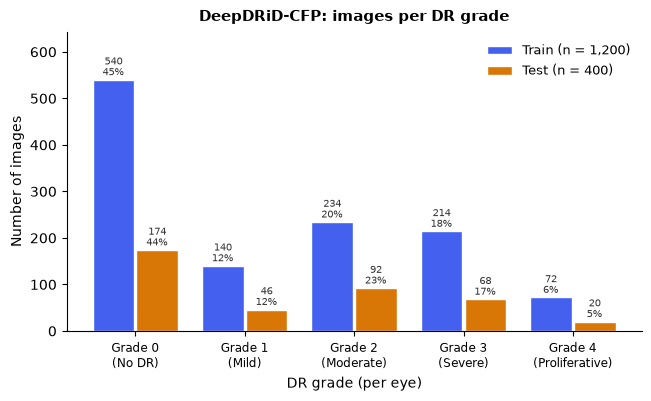

In [3]:
manifest = pd.read_csv(MANIFEST)
print(f'{len(manifest):,} images | ' + ', '.join(f"{s}: {n:,}" for s, n in manifest['split'].value_counts().items()))
missing = [(k, s) for k in K_SHOTS if k > 0 for s in SEEDS
           if not (SPLITS_DIR / f'cfp_{k}shot_s{s}_support.txt').exists()]
assert not missing, f'Missing split files for (k, seed) = {missing}: run src/data/build_splits.py'
print('All split files present.')

plt.rcParams.update({'font.family': 'DejaVu Sans', 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': False})
GRADE_NAMES = ['Grade 0\n(No DR)', 'Grade 1\n(Mild)', 'Grade 2\n(Moderate)',
               'Grade 3\n(Severe)', 'Grade 4\n(Proliferative)']
fig, ax = plt.subplots(figsize=(6.4, 3.9), constrained_layout=True)
grades = np.arange(5)
for i, (split, label, color) in enumerate([('train', 'Train', '#4361EE'), ('test', 'Test', '#D97706')]):
    counts = manifest[manifest['split'] == split]['grade'].value_counts().reindex(grades, fill_value=0)
    bars = ax.bar(grades + (i - 0.5) * 0.40, counts.values, width=0.38, color=color, edgecolor='white',
                  label=f'{label} (n = {counts.sum():,})')
    for bar, n in zip(bars, counts.values):
        ax.text(bar.get_x() + bar.get_width() / 2, n + 6, f'{n:,}\n{n / counts.sum() * 100:.0f}%',
                ha='center', va='bottom', fontsize=7, color='#333333', linespacing=1.1)
ax.set_title('DeepDRiD-CFP: images per DR grade', fontsize=11, fontweight='bold', pad=8)
ax.set_xticks(grades); ax.set_xticklabels(GRADE_NAMES, fontsize=8.5)
ax.set_xlabel('DR grade (per eye)'); ax.set_ylabel('Number of images')
ax.set_ylim(0, manifest['grade'].value_counts().max() * 0.9)
ax.legend(frameon=False, fontsize=9)
plt.show()

## 4 · Single-Run Helper

`src/utils/experiment.py` does the work, the same for every notebook: validation every epoch,
`best.ckpt` (best `val_qwk`) and `last.ckpt` after every epoch, resume from `last.ckpt`, test with the
best checkpoint, k = 0 tests the untrained model. Runs land in `results_shared/<config hash>/`, so the
same configuration is never trained twice, whichever notebook asks for it.

Progress: the outer bar counts runs; below it one bar follows the current run epoch by epoch (loss,
validation QWK, best validation QWK) and one follows the batches of the current epoch.

In [4]:
def spec_overrides(spec: dict) -> list[str]:
    own = [] if spec.get('own_budget', False) else [f'train.epochs={EPOCHS}']
    return own + [f'{k}={v}' for k, v in spec.get('extra', {}).items()]


def run_experiment(name: str, spec: dict, k_shot: int, seed: int, force_retrain: bool = False) -> dict:
    return _run_experiment(name, spec['config'], k_shot, seed, SHARED_RESULTS,
                           overrides=spec_overrides(spec), data_dir=DATA_DIR, force_retrain=force_retrain)


def spec_dir(name: str, k_shot: int, seed: int, variants: dict | None = None):
    # Folder of one run in the shared cache (checkpoints, test_stats.json, geometry.json)
    spec = (variants or {**METHODS, **ABLATIONS})[name]
    return run_dir(SHARED_RESULTS, load_run_config(spec['config'], k_shot, seed, spec_overrides(spec), DATA_DIR))


def run_grid(variants: dict, k_shots: list[int], seeds: list[int], desc: str, train: bool = True) -> pd.DataFrame:
    # Rows of metrics for every (variant, k, seed); train=False only collects runs already in the cache
    rows, missing = [], 0
    pbar = tqdm(total=len(variants) * len(k_shots) * len(seeds), desc=desc, unit='run', dynamic_ncols=True)
    for k in k_shots:
        for name, spec in variants.items():
            for seed in seeds:
                pbar.set_postfix({'variant': name, 'k': k, 'seed': seed})
                if train:
                    m = run_experiment(name, spec, k, seed)
                else:
                    m = cached_metrics(spec['config'], k, seed, SHARED_RESULTS, spec_overrides(spec), DATA_DIR)
                if m is None:
                    missing += 1
                else:
                    rows.append({'Variant': name, 'k': k, 'Seed': seed, **m})
                pbar.update(1)
    pbar.close()
    if missing:
        print(f'{missing} runs not trained yet (set the Phase 2 switch to train them)')
    return pd.DataFrame(rows)

print('run_experiment(), spec_dir() and run_grid() defined.')

run_experiment(), spec_dir() and run_grid() defined.


## 5 · Phase 1 — Main Model Only

Trains only this notebook's main model over every k and seed. The main notebook and the other
direction notebooks do the same for their main model, all into the shared cache.

In [5]:
RUN_PHASE1 = True
df_phase1 = run_grid({MAIN: METHODS[MAIN]}, K_SHOTS, SEEDS, f'Phase 1: {MAIN}', train=RUN_PHASE1)
print('Phase 1 results:', df_phase1.shape)

Phase 1: Direction 3:   0%|          | 0/24 [00:00<?, ?run/s]

Direction 3 | k=32 seed=2:  64%|######4   | 32/50 [00:00<?, ?epoch/s]

  epoch 33:   0%|          | 0/25 [00:00<?, ?batch/s]

  epoch 34:   0%|          | 0/25 [00:00<?, ?batch/s]

  epoch 35:   0%|          | 0/25 [00:00<?, ?batch/s]

...

  epoch 45:   0%|          | 0/25 [00:00<?, ?batch/s]

  epoch 46:   0%|          | 0/25 [00:00<?, ?batch/s]

  epoch 47:   0%|          | 0/25 [00:00<?, ?batch/s]

  epoch 48:   0%|          | 0/25 [00:00<?, ?batch/s]

Phase 1 results: (24, 18)


### 5b · Compare the Main Models (master and Directions 1–3)

Reads finished runs from the shared cache by name; trains nothing. A model appears once its own
notebook has run its Phase 1.

In [6]:
MAIN_MODELS = {                      # display name -> names the run may be recorded under
    'Ours (master)': ['Ours (Full)', 'Ours (master)'],
    'Direction 1':   ['Direction 1'],
    'Direction 2':   ['Direction 2'],
    'Direction 3':   ['Direction 3'],
}
frames = [find_runs(SHARED_RESULTS, names).assign(Model=label) for label, names in MAIN_MODELS.items()]
frames = [f for f in frames if not f.empty and 'qwk' in f]
if frames:
    df_mains = pd.concat(frames, ignore_index=True)
    for m in ('qwk', 'mae', 'odc_full', 'ece', 'nll'):
        if m in df_mains.columns:
            t = df_mains.groupby(['Model', 'k'])[m].mean().unstack('k').reindex(list(MAIN_MODELS)).dropna(how='all')
            print(f'\n{m} (mean over seeds)'); display(t.round(3))
    print('Not run yet:', [m for m in MAIN_MODELS if m not in set(df_mains['Model'])] or 'none')
else:
    print('No main-model runs in the shared cache yet.')


qwk (mean over seeds)


k,-1,0,1,2,4,8,16,32
Model,,,,,,,,
Direction 1,0.802,0.014,0.385,0.373,0.439,0.632,0.671,0.777
Direction 2,0.804,0.006,0.311,0.271,0.381,0.578,0.690,0.754
Direction 3,0.821,0.003,0.302,0.445,0.540,0.656,0.712,0.743



mae (mean over seeds)


k,-1,0,1,2,4,8,16,32
Model,,,,,,,,
Direction 1,0.460,2.480,0.993,0.934,0.912,0.703,0.603,0.533
Direction 2,0.427,1.245,1.058,1.052,0.895,0.770,0.644,0.561
Direction 3,0.408,1.250,1.090,0.890,0.796,0.671,0.605,0.564



odc_full (mean over seeds)


...


ece (mean over seeds)


k,-1,0,1,2,4,8,16,32
Model,,,,,,,,
Direction 1,0.116,0.196,0.188,0.132,0.156,0.080,0.113,0.164
Direction 2,0.109,0.199,0.176,0.182,0.125,0.171,0.194,0.189
Direction 3,0.116,0.205,0.201,0.164,0.113,0.121,0.156,0.185



nll (mean over seeds)


k,-1,0,1,2,4,8,16,32
Model,,,,,,,,
Direction 1,1.139,1.675,1.780,1.639,1.629,1.352,1.429,1.285
Direction 2,1.018,1.944,1.757,1.747,1.580,1.421,1.437,1.387
Direction 3,0.968,1.951,1.846,1.512,1.366,1.366,1.317,1.245


Not run yet: ['Ours (master)']


## 6 · Phase 2 — Baselines and Ablations

Set `RUN_PHASE2 = True` when this direction is the best main model in 5b. With it off, the cells below
still collect whatever is already in the shared cache (for example baselines trained in another
notebook), so the tables and figures fill in as runs become available.

In [7]:
RUN_PHASE2 = False
df_main = run_grid(METHODS, K_SHOTS, SEEDS, 'Phase 2: methods', train=RUN_PHASE2)
df_abl = run_grid(ABLATIONS, ABLATION_K_SHOTS, SEEDS, 'Phase 2: ablations', train=RUN_PHASE2)
print('Methods:', df_main.shape, '| ablations:', df_abl.shape)

Phase 2: methods:   0%|          | 0/240 [00:00<?, ?run/s]

168 runs not trained yet (set the Phase 2 switch to train them)


Phase 2: ablations:   0%|          | 0/198 [00:00<?, ?run/s]

180 runs not trained yet (set the Phase 2 switch to train them)
Methods: (72, 18) | ablations: (18, 18)


## 7 · Results Tables (mean ± std over seeds)

In [8]:
METRICS = ['qwk', 'mae', 'f1', 'auc', 'acc', 'odc_full', 'odc_offdiag', 'ece', 'nll', 'brier']
METRIC_LABELS = {'qwk': 'QWK ↑', 'mae': 'MAE ↓', 'f1': 'Macro-F1 ↑', 'auc': 'AUC ↑', 'acc': 'Accuracy ↑',
                 'odc_full': 'ODC (full) ↑', 'odc_offdiag': 'ODC (off-diag.) ↑', 'ece': 'ECE ↓',
                 'nll': 'NLL ↓', 'brier': 'Brier ↓'}

def aggregate(df: pd.DataFrame, group_cols: list[str]) -> pd.DataFrame:
    rows = []
    for keys, grp in df.groupby(group_cols, sort=False):
        row = dict(zip(group_cols, keys if isinstance(keys, tuple) else [keys]))
        for m in METRICS:
            if m in grp.columns:
                row[f'{m}_mean'] = grp[m].mean()
                row[f'{m}_std'] = grp[m].std(ddof=1) if len(grp) > 1 else 0.0
                row[m] = f"{row[f'{m}_mean']:.3f} ± {row[f'{m}_std']:.3f}"
        rows.append(row)
    return pd.DataFrame(rows)

def k_label(k):
    return {-1: 'full', 0: 'zero-shot'}.get(k, f'{k}-shot')

if not df_main.empty:
    agg_main = aggregate(df_main, ['Variant', 'k'])
    agg_main.to_csv(RESULTS / 'main_results.csv', index=False)
    qwk_table = agg_main.pivot(index='Variant', columns='k', values='qwk').reindex(list(METHODS))
    qwk_table.columns = [k_label(k) for k in qwk_table.columns]
    print('QWK — main comparison'); display(qwk_table)
    for m in ('ece', 'nll'):
        t = agg_main.pivot(index='Variant', columns='k', values=m).reindex(list(METHODS))
        t.columns = [k_label(k) for k in t.columns]
        print(f'{METRIC_LABELS[m]} — main comparison'); display(t)

if not df_abl.empty:
    agg_abl = aggregate(df_abl, ['Variant', 'k'])
    agg_abl.to_csv(RESULTS / 'ablation_results.csv', index=False)
    abl_table = agg_abl.pivot(index='Variant', columns='k', values='qwk').reindex(list(ABLATIONS))
    abl_table.columns = [k_label(k) for k in abl_table.columns]
    print('QWK — Direction 1 ablations'); display(abl_table)

QWK — main comparison


,full,zero-shot,1-shot,2-shot,4-shot,8-shot,16-shot,32-shot
Variant,,,,,,,,
Direction 3,0.821 ± 0.013,0.003 ± 0.000,0.302 ± 0.137,0.445 ± 0.016,0.540 ± 0.061,0.656 ± 0.056,0.712 ± 0.045,0.743 ± 0.013
Direction 2,0.804 ± 0.023,0.006 ± 0.000,0.311 ± 0.100,0.271 ± 0.090,0.381 ± 0.191,0.578 ± 0.122,0.690 ± 0.037,0.754 ± 0.012
Direction 1,0.802 ± 0.023,0.014 ± 0.000,0.385 ± 0.162,0.373 ± 0.098,0.439 ± 0.085,0.632 ± 0.018,0.671 ± 0.056,0.777 ± 0.010
Ours (master),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OrdinalCLIP (matched),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CLIP-DR (matched),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CLIP-LoRA + ordinal losses,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
L2RCLIP (our impl.),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OrdinalCLIP (official),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


ECE ↓ — main comparison


,full,zero-shot,1-shot,2-shot,4-shot,8-shot,16-shot,32-shot
Variant,,,,,,,,
Direction 3,0.116 ± 0.024,0.205 ± 0.000,0.201 ± 0.060,0.164 ± 0.055,0.113 ± 0.025,0.121 ± 0.076,0.156 ± 0.073,0.185 ± 0.020
Direction 2,0.109 ± 0.028,0.199 ± 0.000,0.176 ± 0.058,0.182 ± 0.033,0.125 ± 0.050,0.171 ± 0.081,0.194 ± 0.055,0.189 ± 0.079
Direction 1,0.116 ± 0.048,0.196 ± 0.000,0.188 ± 0.117,0.132 ± 0.034,0.156 ± 0.035,0.080 ± 0.024,0.113 ± 0.063,0.164 ± 0.034
Ours (master),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OrdinalCLIP (matched),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CLIP-DR (matched),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CLIP-LoRA + ordinal losses,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
L2RCLIP (our impl.),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OrdinalCLIP (official),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


NLL ↓ — main comparison


,full,zero-shot,1-shot,2-shot,4-shot,8-shot,16-shot,32-shot
Variant,,,,,,,,
Direction 3,0.968 ± 0.081,1.951 ± 0.000,1.846 ± 0.196,1.512 ± 0.057,1.366 ± 0.087,1.366 ± 0.236,1.317 ± 0.148,1.245 ± 0.094
Direction 2,1.018 ± 0.152,1.944 ± 0.000,1.757 ± 0.108,1.747 ± 0.047,1.580 ± 0.310,1.421 ± 0.299,1.437 ± 0.136,1.387 ± 0.289
Direction 1,1.139 ± 0.240,1.675 ± 0.000,1.780 ± 0.286,1.639 ± 0.177,1.629 ± 0.097,1.352 ± 0.066,1.429 ± 0.368,1.285 ± 0.021
Ours (master),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OrdinalCLIP (matched),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CLIP-DR (matched),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CLIP-LoRA + ordinal losses,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
L2RCLIP (our impl.),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OrdinalCLIP (official),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


QWK — Direction 1 ablations


,full,1-shot,4-shot,8-shot,16-shot,32-shot
Variant,,,,,,
Direction 3,0.821 ± 0.013,0.302 ± 0.137,0.540 ± 0.061,0.656 ± 0.056,0.712 ± 0.045,0.743 ± 0.013
shared κ (temperature),NaN,NaN,NaN,NaN,NaN,NaN
fixed κ (deterministic),NaN,NaN,NaN,NaN,NaN,NaN
expected-similarity scoring,NaN,NaN,NaN,NaN,NaN,NaN
+ SMS,NaN,NaN,NaN,NaN,NaN,NaN
w/o ladder,NaN,NaN,NaN,NaN,NaN,NaN
w/o anchor,NaN,NaN,NaN,NaN,NaN,NaN
w/o κ prior,NaN,NaN,NaN,NaN,NaN,NaN
init: one clinical sentence,NaN,NaN,NaN,NaN,NaN,NaN


## 8 · Figures

Style matches the main notebook (DejaVu Sans, no top/right spines). Method colours follow a
fixed order that passes colour-blind checks; each method also has its own marker.

In [9]:
plt.rcParams.update({'font.family': 'DejaVu Sans', 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': False})

# Fixed colour + marker per method (colour follows the method, never its rank)
STYLE = {
    'Direction 3':                ('#2a78d6', 'o'),
    'Direction 2':                ('#eb6834', 's'),
    'Direction 1':                ('#1baf7a', '^'),
    'Ours (master)':              ('#eda100', 'D'),
    'OrdinalCLIP (matched)':      ('#e87ba4', 'v'),
    'CLIP-DR (matched)':          ('#008300', 'P'),
    'CLIP-LoRA + ordinal losses': ('#6250d6', 'X'),
    'L2RCLIP (our impl.)':        ('#e34948', '*'),
}
CURVE_METHODS = list(STYLE)

### 8a · k-Shot Curves (few-shot points; full data as dashed lines)

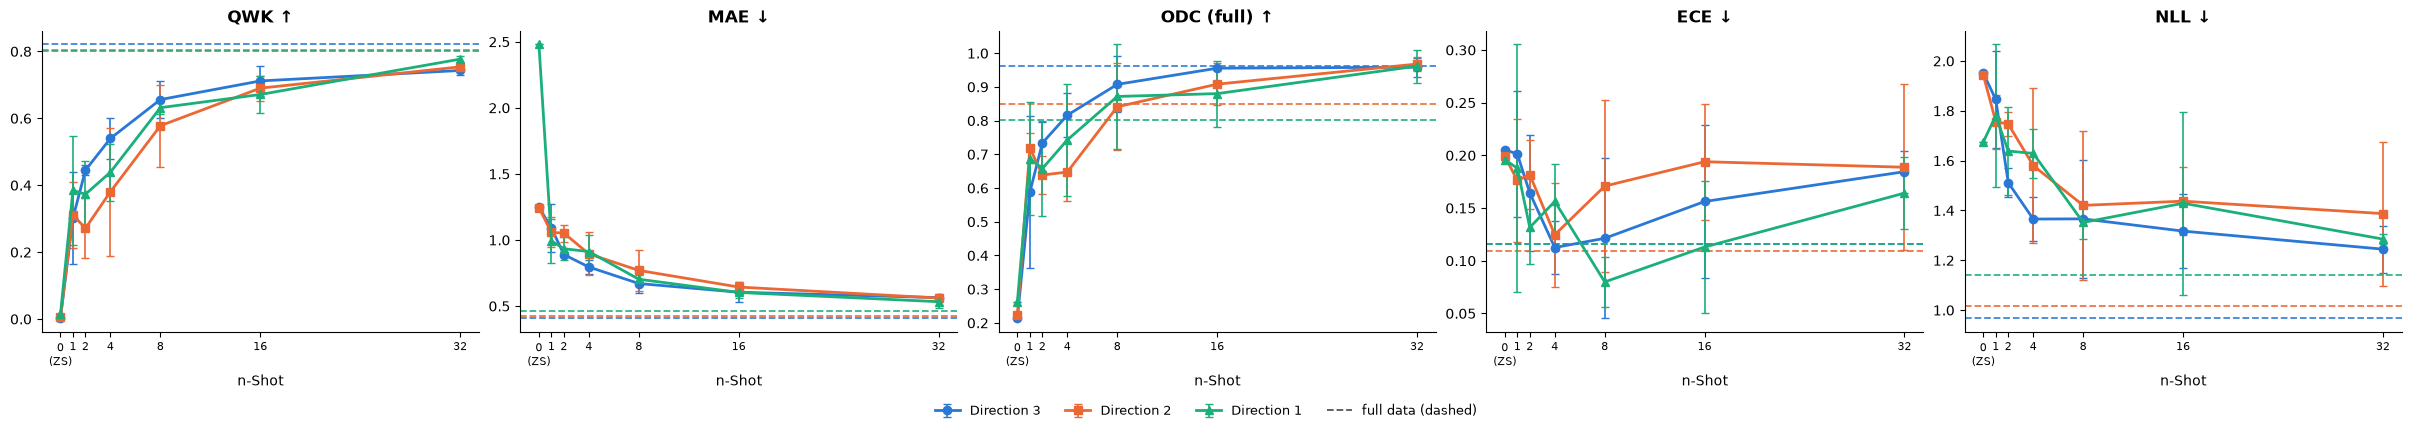

In [10]:
PLOT_METRICS = ['qwk', 'mae', 'odc_full', 'ece', 'nll']
FEW_SHOT_K = [k for k in K_SHOTS if k >= 0]

if not df_main.empty:
    fig, axes = plt.subplots(1, len(PLOT_METRICS), figsize=(4.8 * len(PLOT_METRICS), 4.2), constrained_layout=True)
    for ax, metric in zip(axes, PLOT_METRICS):
        for name in CURVE_METHODS:
            color, marker = STYLE[name]
            sub = agg_main[(agg_main['Variant'] == name) & (agg_main['k'] >= 0)].sort_values('k')
            if sub.empty:
                continue
            ax.errorbar(sub['k'], sub[f'{metric}_mean'], yerr=sub[f'{metric}_std'], color=color, marker=marker,
                        linewidth=2, markersize=6, capsize=3, elinewidth=1.2, label=name)
            full = agg_main[(agg_main['Variant'] == name) & (agg_main['k'] == -1)]
            if not full.empty:
                ax.axhline(float(full[f'{metric}_mean'].iloc[0]), color=color, linestyle='--', linewidth=1.3, alpha=0.9)
        ax.set_title(METRIC_LABELS[metric], fontsize=12, fontweight='bold')
        ax.set_xlabel('n-Shot')
        ax.set_xticks(FEW_SHOT_K)
        ax.set_xticklabels([str(k) if k > 0 else '0\n(ZS)' for k in FEW_SHOT_K], fontsize=8)
        ax.set_xlim(-1.5, max(FEW_SHOT_K) + 1.5)
    handles, labels = axes[0].get_legend_handles_labels()
    handles.append(plt.Line2D([], [], color='#555555', linestyle='--', linewidth=1.3))
    labels.append('full data (dashed)')
    fig.legend(handles, labels, loc='outside lower center', ncol=len(labels), frameon=False, fontsize=9)
    plt.savefig(FIGURES / 'kshot_curves_d3.pdf', bbox_inches='tight', dpi=300)
    plt.savefig(FIGURES / 'kshot_curves_d3.png', bbox_inches='tight', dpi=300)
    plt.show()

### 8b · Ablation Bars (QWK at one k)

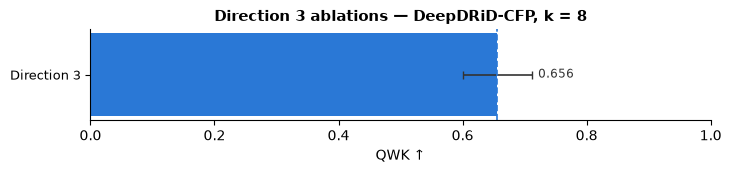

In [11]:
ABLATION_K_PLOT = 8

if not df_abl.empty:
    sub = agg_abl[agg_abl['k'] == ABLATION_K_PLOT].set_index('Variant').reindex(list(ABLATIONS)).dropna(subset=['qwk_mean'])
    fig, ax = plt.subplots(figsize=(7.2, 0.42 * len(sub) + 1.2), constrained_layout=True)
    y = np.arange(len(sub))[::-1]
    colors = ['#2a78d6' if v == 'Direction 3' else '#aab2bd' for v in sub.index]
    ax.barh(y, sub['qwk_mean'], xerr=sub['qwk_std'], color=colors, height=0.6,
            error_kw={'elinewidth': 1.2, 'capsize': 3, 'ecolor': '#333333'})
    for yi, (m, s) in zip(y, zip(sub['qwk_mean'], sub['qwk_std'])):
        ax.text(m + s + 0.01, yi, f'{m:.3f}', va='center', fontsize=8.5, color='#333333')
    if 'Direction 3' in sub.index:
        ax.axvline(sub.loc['Direction 3', 'qwk_mean'], color='#2a78d6', linestyle='--', linewidth=1.2)
    ax.set_yticks(y); ax.set_yticklabels(sub.index, fontsize=9)
    ax.set_xlim(0, 1); ax.set_xlabel('QWK ↑')
    ax.set_title(f'Direction 3 ablations — DeepDRiD-CFP, k = {ABLATION_K_PLOT}', fontsize=11, fontweight='bold')
    plt.savefig(FIGURES / f'ablation_d3_k{ABLATION_K_PLOT}.pdf', bbox_inches='tight', dpi=300)
    plt.savefig(FIGURES / f'ablation_d3_k{ABLATION_K_PLOT}.png', bbox_inches='tight', dpi=300)
    plt.show()

### 8c · Normalized Confusion Matrices (summed over seeds)

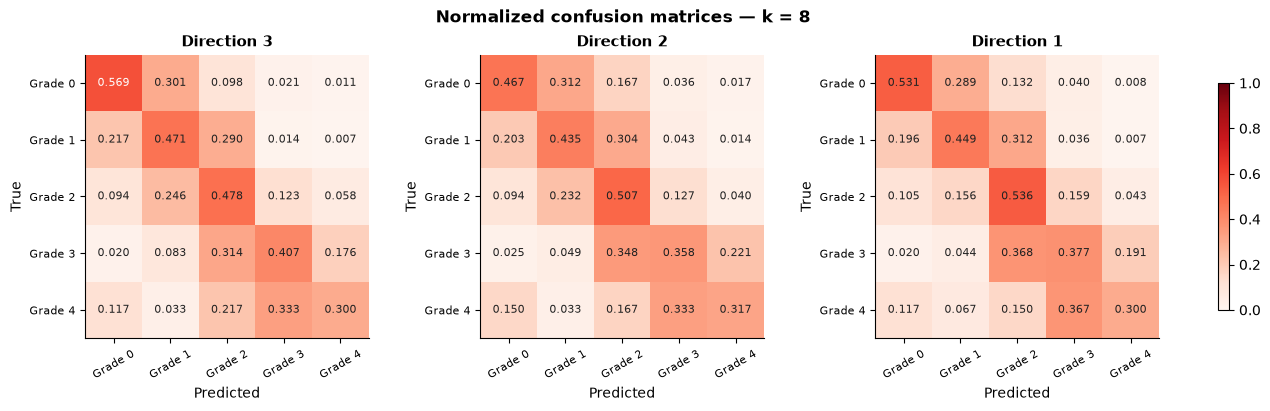

In [15]:
CM_K = 8
CM_METHODS = ['Direction 3', 'Direction 2', 'Direction 1', 'CLIP-DR (matched)']

def summed_confusion(name, k):
    rows = df_main[(df_main['Variant'] == name) & (df_main['k'] == k)]
    if rows.empty:
        return None
    cm = np.sum([np.array(c) for c in rows['confusion_matrix']], axis=0).astype(float)
    return cm / cm.sum(axis=1, keepdims=True).clip(min=1)

if not df_main.empty:
    mats = [(n, summed_confusion(n, CM_K)) for n in CM_METHODS]
    mats = [(n, m) for n, m in mats if m is not None]
    fig, axes = plt.subplots(1, len(mats), figsize=(4.3 * len(mats), 4.0), constrained_layout=True, squeeze=False)
    for ax, (name, cm) in zip(axes[0], mats):
        im = ax.imshow(cm, cmap='Reds', vmin=0, vmax=1)
        for i in range(5):
            for j in range(5):
                ax.text(j, i, f'{cm[i, j]:.3f}', ha='center', va='center', fontsize=8,
                        color='white' if cm[i, j] > 0.55 else '#222222')
        ax.set_xticks(range(5)); ax.set_yticks(range(5))
        ax.set_xticklabels([f'Grade {g}' for g in range(5)], fontsize=8, rotation=30)
        ax.set_yticklabels([f'Grade {g}' for g in range(5)], fontsize=8)
        ax.set_xlabel('Predicted'); ax.set_ylabel('True')
        ax.set_title(name, fontsize=11, fontweight='bold')
    fig.colorbar(im, ax=axes[0].tolist(), shrink=0.8)
    fig.suptitle(f'Normalized confusion matrices — k = {CM_K}', fontsize=12, fontweight='bold')
    plt.savefig(FIGURES / f'confusion_d3_k{CM_K}.pdf', bbox_inches='tight', dpi=300)
    plt.savefig(FIGURES / f'confusion_d3_k{CM_K}.png', bbox_inches='tight', dpi=300)
    plt.show()

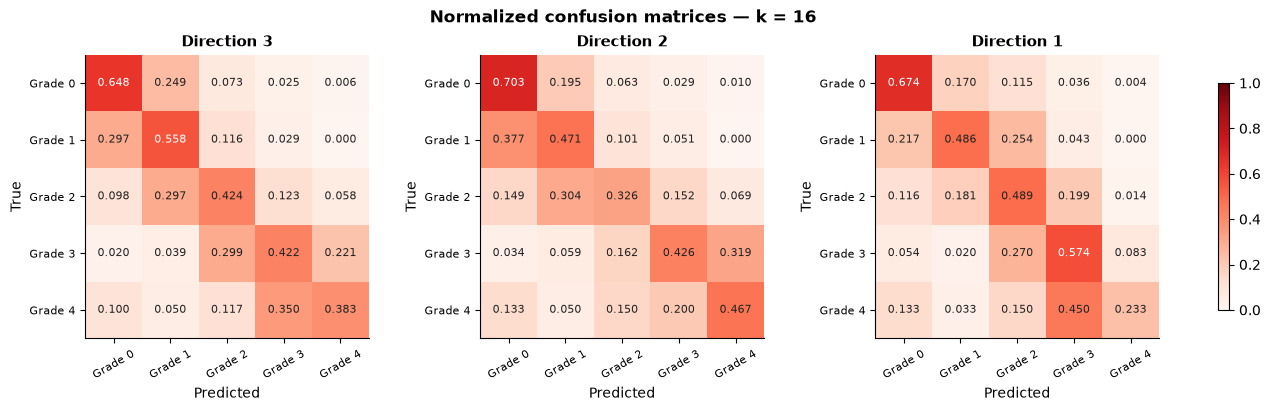

In [16]:
CM_K = 16
CM_METHODS = ['Direction 3', 'Direction 2', 'Direction 1', 'CLIP-DR (matched)']

def summed_confusion(name, k):
    rows = df_main[(df_main['Variant'] == name) & (df_main['k'] == k)]
    if rows.empty:
        return None
    cm = np.sum([np.array(c) for c in rows['confusion_matrix']], axis=0).astype(float)
    return cm / cm.sum(axis=1, keepdims=True).clip(min=1)

if not df_main.empty:
    mats = [(n, summed_confusion(n, CM_K)) for n in CM_METHODS]
    mats = [(n, m) for n, m in mats if m is not None]
    fig, axes = plt.subplots(1, len(mats), figsize=(4.3 * len(mats), 4.0), constrained_layout=True, squeeze=False)
    for ax, (name, cm) in zip(axes[0], mats):
        im = ax.imshow(cm, cmap='Reds', vmin=0, vmax=1)
        for i in range(5):
            for j in range(5):
                ax.text(j, i, f'{cm[i, j]:.3f}', ha='center', va='center', fontsize=8,
                        color='white' if cm[i, j] > 0.55 else '#222222')
        ax.set_xticks(range(5)); ax.set_yticks(range(5))
        ax.set_xticklabels([f'Grade {g}' for g in range(5)], fontsize=8, rotation=30)
        ax.set_yticklabels([f'Grade {g}' for g in range(5)], fontsize=8)
        ax.set_xlabel('Predicted'); ax.set_ylabel('True')
        ax.set_title(name, fontsize=11, fontweight='bold')
    fig.colorbar(im, ax=axes[0].tolist(), shrink=0.8)
    fig.suptitle(f'Normalized confusion matrices — k = {CM_K}', fontsize=12, fontweight='bold')
    plt.savefig(FIGURES / f'confusion_d3_k{CM_K}.pdf', bbox_inches='tight', dpi=300)
    plt.savefig(FIGURES / f'confusion_d3_k{CM_K}.png', bbox_inches='tight', dpi=300)
    plt.show()

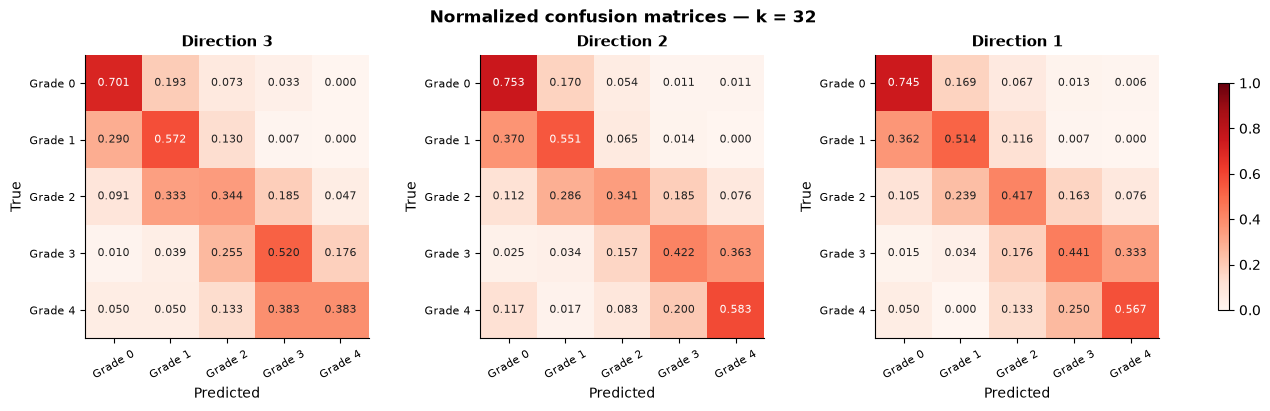

In [17]:
CM_K = 32
CM_METHODS = ['Direction 3', 'Direction 2', 'Direction 1', 'CLIP-DR (matched)']

def summed_confusion(name, k):
    rows = df_main[(df_main['Variant'] == name) & (df_main['k'] == k)]
    if rows.empty:
        return None
    cm = np.sum([np.array(c) for c in rows['confusion_matrix']], axis=0).astype(float)
    return cm / cm.sum(axis=1, keepdims=True).clip(min=1)

if not df_main.empty:
    mats = [(n, summed_confusion(n, CM_K)) for n in CM_METHODS]
    mats = [(n, m) for n, m in mats if m is not None]
    fig, axes = plt.subplots(1, len(mats), figsize=(4.3 * len(mats), 4.0), constrained_layout=True, squeeze=False)
    for ax, (name, cm) in zip(axes[0], mats):
        im = ax.imshow(cm, cmap='Reds', vmin=0, vmax=1)
        for i in range(5):
            for j in range(5):
                ax.text(j, i, f'{cm[i, j]:.3f}', ha='center', va='center', fontsize=8,
                        color='white' if cm[i, j] > 0.55 else '#222222')
        ax.set_xticks(range(5)); ax.set_yticks(range(5))
        ax.set_xticklabels([f'Grade {g}' for g in range(5)], fontsize=8, rotation=30)
        ax.set_yticklabels([f'Grade {g}' for g in range(5)], fontsize=8)
        ax.set_xlabel('Predicted'); ax.set_ylabel('True')
        ax.set_title(name, fontsize=11, fontweight='bold')
    fig.colorbar(im, ax=axes[0].tolist(), shrink=0.8)
    fig.suptitle(f'Normalized confusion matrices — k = {CM_K}', fontsize=12, fontweight='bold')
    plt.savefig(FIGURES / f'confusion_d3_k{CM_K}.pdf', bbox_inches='tight', dpi=300)
    plt.savefig(FIGURES / f'confusion_d3_k{CM_K}.png', bbox_inches='tight', dpi=300)
    plt.show()

### 8d · Error Decay with Ordinal Distance

Share of each true grade's predictions that land |pred − true| = Δ grades away, averaged over
grades and seeds. An ordinal model puts most mass at Δ = 0 and less at every further step.

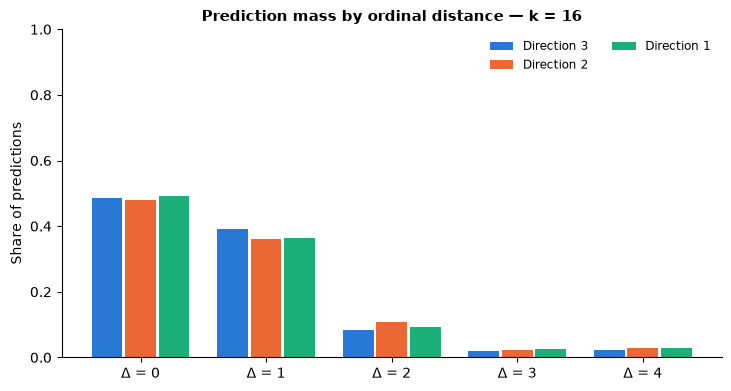

In [18]:
DECAY_K = 16

if not df_main.empty:
    fig, ax = plt.subplots(figsize=(7.2, 3.8), constrained_layout=True)
    names = [n for n in CURVE_METHODS if ((df_main['Variant'] == n) & (df_main['k'] == DECAY_K)).any()]
    width = 0.8 / max(1, len(names))
    for i, name in enumerate(names):
        mass = np.mean([np.array(m) for m in df_main[(df_main['Variant'] == name) & (df_main['k'] == DECAY_K)]['mean_mass_by_dist']], axis=0)
        ax.bar(np.arange(5) + (i - (len(names) - 1) / 2) * width, mass, width=width * 0.92,
               color=STYLE[name][0], label=name)
    ax.set_xticks(range(5)); ax.set_xticklabels([f'Δ = {d}' for d in range(5)])
    ax.set_ylabel('Share of predictions'); ax.set_ylim(0, 1)
    ax.set_title(f'Prediction mass by ordinal distance — k = {DECAY_K}', fontsize=11, fontweight='bold')
    ax.legend(frameon=False, fontsize=8.5, ncol=2)
    plt.savefig(FIGURES / f'error_decay_d3_k{DECAY_K}.pdf', bbox_inches='tight', dpi=300)
    plt.savefig(FIGURES / f'error_decay_d3_k{DECAY_K}.png', bbox_inches='tight', dpi=300)
    plt.show()

### 8e · Grade Distributions During Training (Direction 3)

From `geometry.json`: the concentration κ of each grade (lower = broader, more ambiguous grade),
the share of satisfied ladder constraints on the means, the drift of each mean from its zero-shot
start, and the final distances between grade means.

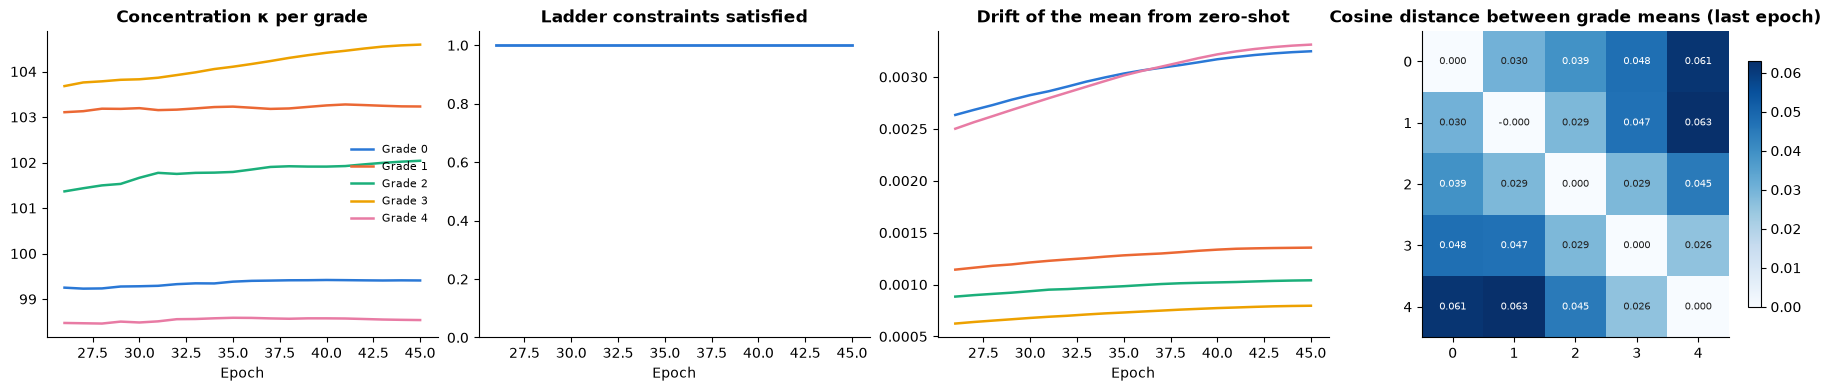

In [23]:
GEO_K, GEO_SEED = 16, 3
geo_file = spec_dir('Direction 3', GEO_K, GEO_SEED) / 'geometry.json'

if geo_file.exists():
    geo = json.load(open(geo_file))
    epochs = [g['epoch'] for g in geo]
    kappa = np.array([g['kappa'] for g in geo])
    drift = np.array([g['anchor_drift'] for g in geo])
    grade_colors = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4']
    fig, axes = plt.subplots(1, 4, figsize=(18, 3.8), constrained_layout=True)
    for k in range(kappa.shape[1]):
        axes[0].plot(epochs, kappa[:, k], color=grade_colors[k], linewidth=1.8, label=f'Grade {k}')
        axes[2].plot(epochs, drift[:, k], color=grade_colors[k], linewidth=1.8, label=f'Grade {k}')
    axes[0].set_title('Concentration κ per grade', fontweight='bold'); axes[0].set_xlabel('Epoch')
    axes[0].legend(frameon=False, fontsize=8)
    axes[1].plot(epochs, [g['ladder_satisfied_frac'] for g in geo], color='#2a78d6', linewidth=2)
    axes[1].set_ylim(0, 1.05); axes[1].set_xlabel('Epoch')
    axes[1].set_title('Ladder constraints satisfied', fontweight='bold')
    axes[2].set_title('Drift of the mean from zero-shot', fontweight='bold'); axes[2].set_xlabel('Epoch')
    dist = np.array(geo[-1]['distance_matrix'])
    im = axes[3].imshow(dist, cmap='Blues')
    for i in range(5):
        for j in range(5):
            axes[3].text(j, i, f'{dist[i, j]:.3f}', ha='center', va='center', fontsize=7.5,
                         color='white' if dist[i, j] > dist.max() * 0.6 else '#222222')
    axes[3].set_xticks(range(5)); axes[3].set_yticks(range(5))
    axes[3].set_title('Cosine distance between grade means (last epoch)', fontweight='bold')
    fig.colorbar(im, ax=axes[3], shrink=0.8)
    plt.savefig(FIGURES / f'geometry_d3_k{GEO_K}_s{GEO_SEED}.pdf', bbox_inches='tight', dpi=300)
    plt.show()
else:
    print(f'No geometry file yet: {geo_file}')